# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [1]:
# Uncomment and run if required
#!pip install transformers torchvision torch accelerate

In [2]:
from transformers import CLIPModel, CLIPProcessor
import torch

clip_model_name = "openai/clip-vit-base-patch32"
clip_model     = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)

# Set model to evaluation mode, as we are not training it
clip_model.eval()

# Check for accelerators
device = "cpu" # Default to CPU
if torch.cuda.is_available():
    device = "cuda" # Use GPU if available
elif torch.backends.mps.is_available():
    device = "mps"

clip_model.to(device)

print(f"Using device: {device}")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

c:\Users\Charl\OneDrive\Documents\Education\Programs\UofT - Data Science Institute\Machine Learning Foundations\deep_learning\deep-learning-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Charl\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(messa

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (5 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Using device: cpu


Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [3]:
from torchvision import datasets
from torch.utils.data import DataLoader
import os

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def collate_clip(batch):
    imgs, labels = zip(*batch) # Unzip the batch into images and labels
    proc = clip_processor(images=list(imgs),
                        return_tensors="pt",
                        padding=True) # Process images with CLIPProcessor
    # Send pixel_values to GPU/CPU now; labels stay on CPU for metrics
    return proc["pixel_values"].to(device), torch.tensor(labels)

# Downloaded once to a cache folder in your user directory (kept out of the git repo)
data_root = os.path.join(os.path.expanduser("~"), ".cache", "fashion_mnist")
test_dataset = datasets.FashionMNIST(root=data_root, train=False, download=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=True, collate_fn=collate_clip)

print(f"{len(test_dataset):,} test images in {len(test_loader):,} batches of 16")
















































































































100%|██████████| 26.4M/26.4M [00:14<00:00, 1.77MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 318kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 4.98MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]

10,000 test images in 625 batches of 16


If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

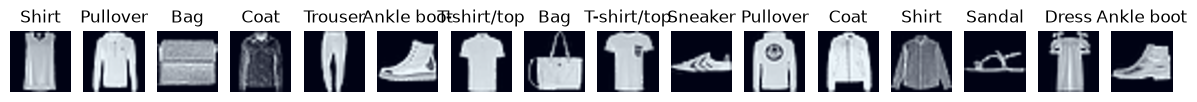

In [4]:
import matplotlib.pyplot as plt

# Display the first batch of images from `test_loader`

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()  # Move images to CPU for plotting
    # Renormalize to [0, 1] for visualization
    images = (images - images.min()) / (images.max() - images.min())
    _, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASS_NAMES[label.item()])
        ax.axis('off')
    plt.show()

show_batch(test_loader)

We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [5]:
def get_text_embeddings(class_names: list[str]) -> torch.Tensor:
    """    Get text embeddings for the given class names using CLIP.
    Args:
        class_names (list[str]): List of class names to encode.
    Returns:
        torch.Tensor: Normalized text embeddings for the class names.
    """
    tokenized = clip_processor(text=class_names,
                               padding=True,
                               return_tensors="pt").to(device)
    
    with torch.no_grad():
        text_embeddings = clip_model.get_text_features(**tokenized)
    # transformers 5.x returns an output object with the projected embeddings in .pooler_output
    # (older versions return the tensor directly)
    if not isinstance(text_embeddings, torch.Tensor):
        text_embeddings = text_embeddings.pooler_output

    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)

    return text_feats

def get_image_embeddings(images: torch.Tensor) -> torch.Tensor:
    """    Get image embeddings for the given images using CLIP.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = clip_model.get_image_features(pixel_values=images)
    if not isinstance(image_embeddings, torch.Tensor):  # transformers 5.x: see get_text_embeddings
        image_embeddings = image_embeddings.pooler_output

    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

    return image_feats

In [6]:
import numpy as np

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    return (image_feats @ text_feats.T).numpy()

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    return np.argmax(similarity, axis=1)

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ ] For each batch of images:
    - [ ] Get image embeddings using the `get_image_embeddings` function.
    - [ ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ ] Save the predictions so that we can build a confusion matrix later.
- [ ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

125/625 batches (58s)
250/625 batches (114s)
375/625 batches (169s)
500/625 batches (220s)
625/625 batches (272s)
Image embeddings: (10000, 512)

Zero-shot accuracy with the bare class names as prompts: 0.6240
Accuracy by class:
  T-shirt/top  0.769
  Trouser      0.931
  Pullover     0.306
  Dress        0.504
  Coat         0.690
  Sandal       0.393
  Shirt        0.042
  Sneaker      0.950
  Bag          0.958
  Ankle boot   0.697


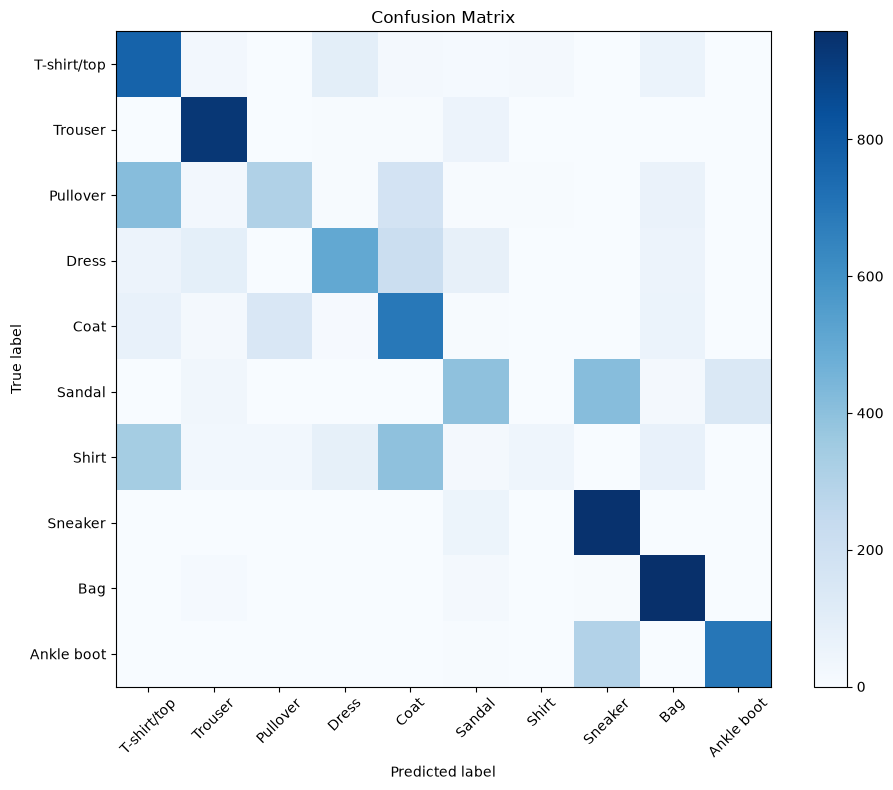

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix
import time

# Text embeddings for the bare class names (only needs to be done once)
text_feats = get_text_embeddings(CLASS_NAMES)

y_true, y_pred = [], []
# The image embeddings don't depend on the text prompts, so we keep them: the prompt-engineering,
# UMAP and mini-experiment sections below reuse them instead of running all 10,000 images through CLIP again
all_image_feats = []

start = time.time()
for batch_idx, (pixel_values, labels) in enumerate(test_loader):
    image_feats = get_image_embeddings(pixel_values)
    similarity = get_cosine_similarity(image_feats, text_feats)
    y_pred.extend(get_predictions(similarity))
    y_true.extend(labels.numpy())
    all_image_feats.append(image_feats.cpu())
    if (batch_idx + 1) % 125 == 0:
        print(f"{batch_idx + 1}/{len(test_loader)} batches ({time.time() - start:.0f}s)")

y_true, y_pred = np.array(y_true), np.array(y_pred)
all_image_feats = torch.cat(all_image_feats)
print(f"Image embeddings: {tuple(all_image_feats.shape)}")

# Report the accuracy of the predictions
baseline_accuracy = accuracy_score(y_true, y_pred)
print(f"\nZero-shot accuracy with the bare class names as prompts: {baseline_accuracy:.4f}")
print("Accuracy by class:")
for c, name in enumerate(CLASS_NAMES):
    print(f"  {name:<12} {np.mean(y_pred[y_true == c] == c):.3f}")

# Report the confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach?

**Answer:** The zero-shot baseline reaches **62.40%** on the 10,000 test images without seeing a single labelled Fashion-MNIST example. My Assignment 1 models, trained on the 60,000 labelled training images, did much better: **91.34%** for the final CNN, and 84.10% even for the simple linear baseline.

| Class | Zero-shot CLIP (bare class names) | A1 final CNN |
|---|---|---|
| T-shirt/top | 76.9% | 86.5% |
| Trouser | 93.1% | 97.6% |
| Pullover | 30.6% | 87.6% |
| Dress | 50.4% | 91.9% |
| Coat | 69.0% | 84.8% |
| Sandal | 39.3% | 97.3% |
| Shirt | 4.2% | 75.6% |
| Sneaker | 95.0% | 98.4% |
| Bag | 95.8% | 98.2% |
| Ankle boot | 69.7% | 95.5% |

The gap is very uneven. On distinctive classes (Bag, Sneaker, Trouser), CLIP is within 5 points of the CNN. It fails on similar-looking classes: only 42 of the 1,000 shirts are recognised (most are labelled Coat or T-shirt/top), about 4 in 10 pullovers are called T-shirt/top, and about 4 in 10 sandals and 3 in 10 ankle boots are called Sneaker (see the confusion matrix).

**Strengths**
- No labelled data and no training: it works out of the box.
- Flexible: the classes are just text, so the same model can classify a new set of labels by changing the class names.
- Its general visual knowledge already handles distinctive objects almost as well as a trained model.

**Weaknesses**
- Much lower accuracy on this task, especially for fine-grained classes.
- Domain mismatch: CLIP learned from colour, high-resolution web photos with captions, while these are 28×28 grayscale thumbnails blown up to 224×224, where collars, buttons or fabric thickness are barely visible.
- Ambiguous class names: in everyday language "shirt" can also mean a T-shirt and "top" can mean almost anything, but the dataset uses them as distinct classes that the model knows nothing about.
- It is sensitive to the prompt wording (next section), and it is a much larger, slower model: encoding the 10,000 test images took 272 seconds on my CPU.

## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

bare class names (baseline)              accuracy 0.6240
a photo of a ...                         accuracy 0.6033
black-and-white photo                    accuracy 0.6623
descriptive (distinguishing features)    accuracy 0.6495
low-res product photo + descriptive      accuracy 0.7014

Best prompt set: 'low-res product photo + descriptive' with accuracy 0.7014 (+7.7 points vs the bare class names)
Accuracy by class (best prompts vs baseline):
  T-shirt/top  0.569   (baseline 0.769)
  Trouser      0.800   (baseline 0.931)
  Pullover     0.845   (baseline 0.306)
  Dress        0.908   (baseline 0.504)
  Coat         0.322   (baseline 0.690)
  Sandal       0.845   (baseline 0.393)
  Shirt        0.119   (baseline 0.042)
  Sneaker      0.776   (baseline 0.950)
  Bag          0.979   (baseline 0.958)
  Ankle boot   0.851   (baseline 0.697)


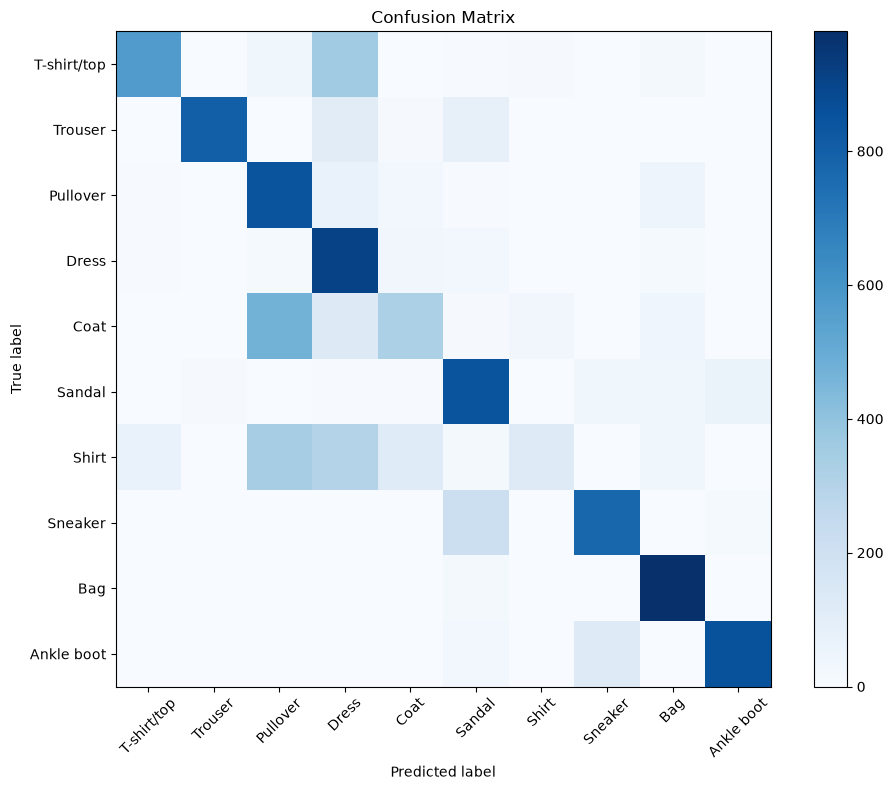

In [8]:
def evaluate_prompts(prompts):
    """Zero-shot accuracy and predictions for one prompt per class, using the stored image embeddings."""
    feats = get_text_embeddings(prompts)
    preds = get_predictions(get_cosine_similarity(all_image_feats, feats))
    return accuracy_score(y_true, preds), preds


# Several prompt sets, from simple templates to descriptions that spell out how the confused classes differ.
# Every set lists the classes in the same order as CLASS_NAMES.
prompt_sets = {
    "bare class names (baseline)": CLASS_NAMES,
    "a photo of a ...": [
        "a photo of a t-shirt", "a photo of trousers", "a photo of a pullover", "a photo of a dress",
        "a photo of a coat", "a photo of a sandal", "a photo of a shirt", "a photo of a sneaker",
        "a photo of a bag", "a photo of an ankle boot"],
    "black-and-white photo": [
        "a black and white photo of a t-shirt", "a black and white photo of trousers",
        "a black and white photo of a pullover sweater", "a black and white photo of a dress",
        "a black and white photo of a coat", "a black and white photo of a sandal",
        "a black and white photo of a shirt", "a black and white photo of a sneaker",
        "a black and white photo of a bag", "a black and white photo of an ankle boot"],
    "descriptive (distinguishing features)": [
        "a photo of a short-sleeved t-shirt or tank top",
        "a photo of a pair of trousers",
        "a photo of a long-sleeved knitted pullover sweater",
        "a photo of a woman's dress",
        "a photo of a thick winter coat or jacket with a zipper",
        "a photo of an open summer sandal with straps",
        "a photo of a button-up shirt with a collar",
        "a photo of a sneaker, a sports shoe",
        "a photo of a handbag or bag",
        "a photo of an ankle boot"],
    "low-res product photo + descriptive": [
        "a low resolution grayscale product photo of a short-sleeved t-shirt",
        "a low resolution grayscale product photo of a pair of trousers",
        "a low resolution grayscale product photo of a long-sleeved pullover sweater",
        "a low resolution grayscale product photo of a dress",
        "a low resolution grayscale product photo of a coat",
        "a low resolution grayscale product photo of a sandal",
        "a low resolution grayscale product photo of a button-up shirt with a collar",
        "a low resolution grayscale product photo of a sneaker",
        "a low resolution grayscale product photo of a bag",
        "a low resolution grayscale product photo of an ankle boot"],
}

prompt_results = {}
for name, prompts in prompt_sets.items():
    accuracy, preds = evaluate_prompts(prompts)
    prompt_results[name] = (accuracy, preds)
    print(f"{name:<40} accuracy {accuracy:.4f}")

best_name = max(prompt_results, key=lambda name: prompt_results[name][0])
best_accuracy, best_preds = prompt_results[best_name]
print(f"\nBest prompt set: '{best_name}' with accuracy {best_accuracy:.4f} "
      f"({(best_accuracy - baseline_accuracy) * 100:+.1f} points vs the bare class names)")
print("Accuracy by class (best prompts vs baseline):")
for c, name in enumerate(CLASS_NAMES):
    print(f"  {name:<12} {np.mean(best_preds[y_true == c] == c):.3f}   (baseline {np.mean(y_pred[y_true == c] == c):.3f})")

plot_confusion_matrix(y_true, best_preds, CLASS_NAMES)

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

**Answer:** I compared five prompt sets, all scored on the same stored image embeddings:

| Prompt set | Accuracy | Change vs bare names |
|---|---|---|
| Bare class names (baseline) | 62.40% | – |
| "a photo of a …" | 60.33% | −2.07 points |
| "a black and white photo of a …" | 66.23% | +3.83 points |
| Descriptive (e.g. "a photo of a button-up shirt with a collar") | 64.95% | +2.55 points |
| "a low resolution grayscale product photo of a …" + descriptive | **70.14%** | **+7.74 points** |

The best prompts gave a real improvement of 7.7 points, but accuracy is still 21 points below the A1 CNN (91.34%).

What I learned about the model:
- **Describing the kind of image helped more than describing the clothes.** Just saying "black and white photo" gained 3.8 points, and "low resolution grayscale product photo" gave the best result. The standard "a photo of a …" template, which helps on everyday photos, made things slightly worse here. CLIP matches the whole picture, not just the object, so the prompt should describe what the images actually look like.
- **Prompts move errors around more than they remove them.** With the best prompts, Pullover rose from 30.6% to 84.5%, Sandal from 39.3% to 84.5% and Dress from 50.4% to 90.8%. But Coat fell from 69.0% to 32.2% (almost half the coats are now called Pullover), T-shirt/top from 76.9% to 56.9% (over a third now called Dress) and Sneaker from 95.0% to 77.6% (about a fifth called Sandal). Making one class's text more attractive pulls images away from its neighbours.
- **Shirt barely responds to prompts** (4.2% → 11.9%). The UMAP plot below suggests why: the shirt images sit among the pullovers and coats.

With more effort I could probably gain a few more points: choose the best prompt for each class separately (Coat and T-shirt/top did better with their bare names), average several prompts per class (tried in my mini-experiment), or use a larger CLIP model. That selection should be done on a validation split: I picked the best of five sets using test accuracy, so 70.14% is slightly optimistic. I don't think prompts alone can close the gap to the CNN, though, because some classes overlap in the image embeddings themselves; that would need some labelled data, for example a small classifier trained on CLIP's embeddings.

## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [9]:
# Uncomment the following line to install UMAP if you haven't already
# !pip install umap-learn

Embeddings: (10000, 512)


c:\Users\Charl\OneDrive\Documents\Education\Programs\UofT - Data Science Institute\Machine Learning Foundations\deep_learning\deep-learning-env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Charl\OneDrive\Documents\Education\Programs\UofT - Data Science Institute\Machine Learning Foundations\deep_learning\deep-learning-env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


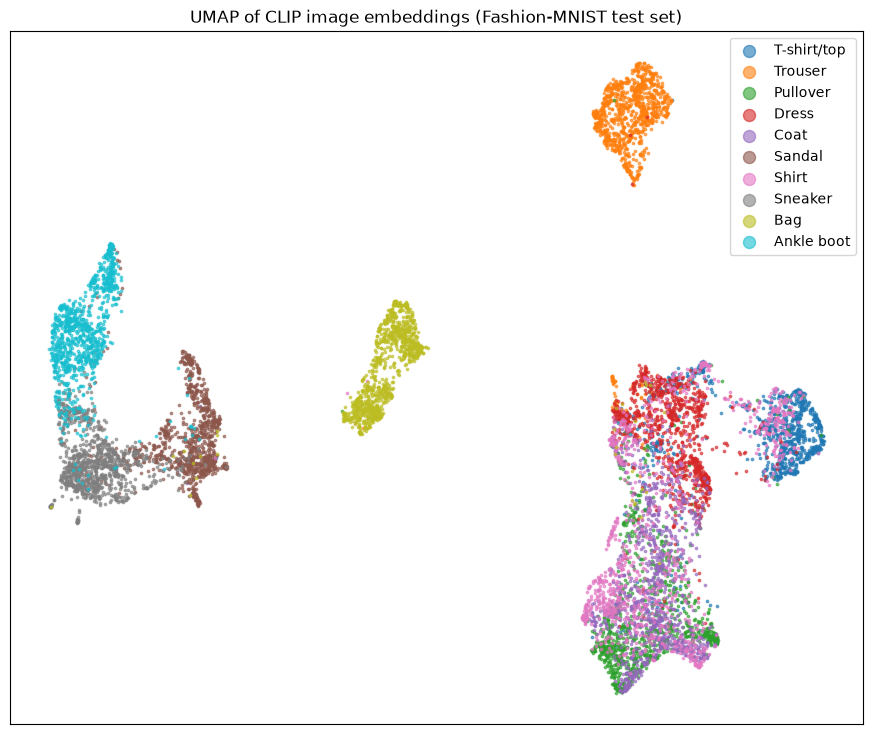

In [10]:
from umap import UMAP

# ------------------------------------------------------------
# 1. Collect image embeddings
# ------------------------------------------------------------
# These were already computed with get_image_embeddings for the whole test set in the baseline loop above
# (and stored with their labels), so reuse them rather than running the 10,000 images through CLIP again.
all_img_emb = all_image_feats.numpy()
all_labels  = y_true
print("Embeddings:", all_img_emb.shape)

# ------------------------------------------------------------
# 2. Fit UMAP
# ------------------------------------------------------------
reducer = UMAP(n_components=2, random_state=42)
embedding_2d = reducer.fit_transform(all_img_emb)

# ------------------------------------------------------------
# 3. Plot coloured by ground-truth label
# ------------------------------------------------------------
plt.figure(figsize=(11, 9))
for c, name in enumerate(CLASS_NAMES):
    points = embedding_2d[all_labels == c]
    plt.scatter(points[:, 0], points[:, 1], s=3, alpha=0.6, color=plt.cm.tab10(c), label=name)
plt.legend(markerscale=5, loc="best")
plt.title("UMAP of CLIP image embeddings (Fashion-MNIST test set)")
plt.xticks([])
plt.yticks([])
plt.show()

The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?

**Answer:** Yes. The plot shows four groups:
- **Trouser** and **Bag** each form a compact cluster far from everything else, so the model has no trouble telling them apart from the other classes (they were also among the best classes at baseline: 93.1% and 95.8%).
- **Footwear** forms a separate group. Inside it, Ankle boot has its own lobe, while Sneaker and Sandal sit side by side and touch, with some sandals mixed in among the sneakers.
- **Upper-body clothing and dresses** form one large blob. T-shirt/top makes a fairly clear sub-cluster at one edge and Dress a region at the top, but **Pullover, Coat and Shirt are almost completely mixed together**, and shirts are also scattered among the T-shirts and dresses.

These overlaps match the worst errors in the confusion matrices (Coat ↔ Pullover, and Shirt spread over four classes). UMAP only uses the image embeddings, so these confusions come from the images themselves and no prompt can fully fix them, which is why Shirt stayed at 12% or below even with the best prompts. Where the image clusters are separate, the mistakes come from the text side and better prompts can fix them: Sandal rose from 39.3% to 84.5%. (UMAP squeezes 512 dimensions into 2, so it can exaggerate some overlaps, but here it agrees with the confusion matrices.)

## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

40 prompts (4 per class)
Baseline (bare class names)                                    0.6240
Best single prompt set ('low-res product photo + descriptive') 0.7014
Multiple descriptions - best-matching prompt (rule 1)          0.6176
Multiple descriptions - averaged per class (rule 2)            0.6532

Accuracy by class, rule 1 vs rule 2:
  T-shirt/top  0.824   0.797
  Trouser      0.767   0.896
  Pullover     0.909   0.928
  Dress        0.620   0.611
  Coat         0.184   0.188
  Sandal       0.162   0.325
  Shirt        0.112   0.135
  Sneaker      0.996   0.994
  Bag          0.918   0.958
  Ankle boot   0.684   0.700

Most frequently chosen prompt for images of each class:
  T-shirt/top  -> 'a photo of a short-sleeved t-shirt' (694 images)
  Trouser      -> 'a photo of trousers' (456 images)
  Pullover     -> 'a photo of a pullover' (901 images)
  Dress        -> 'a photo of a woman's dress' (572 images)
  Coat         -> 'a photo of a pullover' (687 images)
  Sandal       -> '

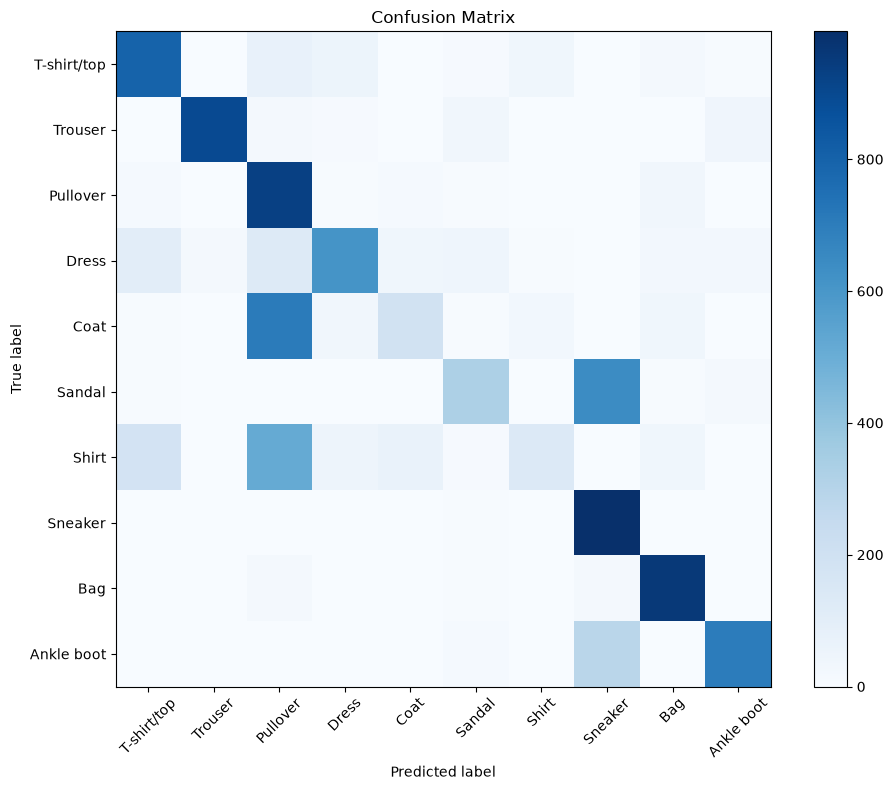

In [11]:
# Mini-experiment B: multiple descriptions per class
multi_prompts = {
    "T-shirt/top": ["a photo of a t-shirt", "a photo of a top", "a photo of a tank top",
                    "a photo of a short-sleeved t-shirt"],
    "Trouser":     ["a photo of trousers", "a photo of pants", "a photo of jeans", "a photo of a pair of trousers"],
    "Pullover":    ["a photo of a pullover", "a photo of a sweater", "a photo of a jumper",
                    "a photo of a long-sleeved knitted sweater"],
    "Dress":       ["a photo of a dress", "a photo of a gown", "a photo of a woman's dress",
                    "a photo of a summer dress"],
    "Coat":        ["a photo of a coat", "a photo of a jacket", "a photo of a winter coat",
                    "a photo of a coat with a zipper"],
    "Sandal":      ["a photo of a sandal", "a photo of a strappy sandal", "a photo of a flip-flop",
                    "a photo of an open-toe sandal"],
    "Shirt":       ["a photo of a shirt", "a photo of a button-up shirt", "a photo of a dress shirt",
                    "a photo of a blouse"],
    "Sneaker":     ["a photo of a sneaker", "a photo of a running shoe", "a photo of a sports shoe",
                    "a photo of a trainer"],
    "Bag":         ["a photo of a bag", "a photo of a handbag", "a photo of a purse", "a photo of a tote bag"],
    "Ankle boot":  ["a photo of an ankle boot", "a photo of a boot", "a photo of a leather boot",
                    "a photo of a short boot"],
}

prompt_texts, prompt_class = [], []
for c, name in enumerate(CLASS_NAMES):
    for prompt in multi_prompts[name]:
        prompt_texts.append(prompt)
        prompt_class.append(c)
prompt_class = np.array(prompt_class)
print(f"{len(prompt_texts)} prompts ({len(prompt_texts) // len(CLASS_NAMES)} per class)")

multi_text_feats = get_text_embeddings(prompt_texts).cpu()   # on the CPU, like all_image_feats
multi_similarity = get_cosine_similarity(all_image_feats, multi_text_feats)   # shape (10000, 40)

# Rule 1 (as in the instructions): the image gets the class of whichever prompt matches it best,
# so the model is correct if it picks ANY of the prompts that belong to the correct class
multi_preds_any = prompt_class[np.argmax(multi_similarity, axis=1)]
multi_accuracy_any = accuracy_score(y_true, multi_preds_any)

# Rule 2, for comparison (prompt ensembling, as in the CLIP paper): average each class's prompt embeddings
# into a single class embedding, then classify as before
class_feats = torch.stack([multi_text_feats[torch.from_numpy(prompt_class == c)].mean(dim=0)
                           for c in range(len(CLASS_NAMES))])
class_feats = class_feats / class_feats.norm(dim=-1, keepdim=True)
multi_preds_mean = get_predictions(get_cosine_similarity(all_image_feats, class_feats))
multi_accuracy_mean = accuracy_score(y_true, multi_preds_mean)

summary = {
    "Baseline (bare class names)": baseline_accuracy,
    f"Best single prompt set ('{best_name}')": best_accuracy,
    "Multiple descriptions - best-matching prompt (rule 1)": multi_accuracy_any,
    "Multiple descriptions - averaged per class (rule 2)": multi_accuracy_mean,
}
for name, accuracy in summary.items():
    print(f"{name:<62} {accuracy:.4f}")

print("\nAccuracy by class, rule 1 vs rule 2:")
for c, name in enumerate(CLASS_NAMES):
    mask = y_true == c
    print(f"  {name:<12} {np.mean(multi_preds_any[mask] == c):.3f}   {np.mean(multi_preds_mean[mask] == c):.3f}")

# Which description "wins" most often for each class? (rule 1)
winning_prompt = np.argmax(multi_similarity, axis=1)
print("\nMost frequently chosen prompt for images of each class:")
for c, name in enumerate(CLASS_NAMES):
    counts = np.bincount(winning_prompt[y_true == c], minlength=len(prompt_texts))
    top = int(np.argmax(counts))
    print(f"  {name:<12} -> '{prompt_texts[top]}' ({counts[top]} images)")

plot_confusion_matrix(y_true, multi_preds_any if multi_accuracy_any >= multi_accuracy_mean else multi_preds_mean,
                      CLASS_NAMES)

### Short Report

In this section, you will write a short report summarizing your findings from the mini-experiment. The report should include the following sections:

- **Introduction**: Briefly describe the mini-experiment you conducted and its objectives.
- **Methodology**: Explain the steps you took to conduct the experiment, including any modifications you made to the code or model.
- **Results**: Present the results of your experiment.
- **Discussion**: Reflect on the performance of the model and the implications of your findings. Consider the strengths and weaknesses of zero-shot transformers versus a trained CNN.

#### Introduction
For the mini-experiment I chose **B. Multiple-Description Classification**. Instead of one prompt per class, each class gets four descriptions (for example "a photo of a sneaker", "a photo of a running shoe", "a photo of a sports shoe" and "a photo of a trainer"). The aim was to see whether giving CLIP several ways to recognise each class beats a single prompt, and which way of combining the descriptions works best.

#### Methodology
- I wrote 4 prompts per class (40 in total), mixing synonyms ("pants", "jeans"), sub-types ("tote bag", "flip-flop") and short descriptions ("a photo of a coat with a zipper").
- I encoded the prompts with `get_text_embeddings` and compared them with the 10,000 image embeddings stored during the baseline, so the images didn't need to be encoded again.
- **Rule 1** (as in the instructions): each image gets the class of its best-matching prompt, so the model is correct if *any* of the correct class's prompts wins.
- **Rule 2** (for comparison): average each class's 4 prompt embeddings into one class embedding (prompt ensembling, as in the CLIP paper), then classify as in the baseline.
- I compared both rules with the baseline and the best single prompt set, overall and per class, and counted which prompt won most often for each class.

#### Results

| Method | Accuracy |
|---|---|
| Baseline (bare class names) | 62.40% |
| Best single prompt set (low-res product photo + descriptive) | **70.14%** |
| Multiple descriptions, rule 1 (best-matching prompt) | 61.76% |
| Multiple descriptions, rule 2 (averaged per class) | 65.32% |

- Rule 1 was slightly *worse* than the baseline (−0.64 points). Rule 2 beat rule 1 by 3.56 points and the baseline by 2.92 points, but stayed 4.82 points below the best single prompt set.
- Multiple descriptions helped Pullover (90.9% with rule 1 and 92.8% with rule 2, vs 30.6% at baseline) and Sneaker (99.6% / 99.4% vs 95.0%), but hurt Coat (18.4% / 18.8% vs 69.0%) and Sandal (16.2% / 32.5% vs 39.3%).
- The winning-prompt counts show why: "a photo of a pullover" was the best match for 687 of the 1,000 coats and 504 of the shirts, and "a photo of a running shoe" for 789 of the 1,000 sandals. In the confusion matrix (rule 2), about 7 in 10 coats are labelled Pullover and about 6 in 10 sandals Sneaker.

#### Discussion
- **More prompts are not automatically better.** With rule 1, every extra prompt is one more chance for a *wrong* class to win, and a single broad prompt like "a running shoe" or "a pullover" captures images of neighbouring classes. Averaging dilutes such prompts, which is why rule 2 beat rule 1 on 7 of the 10 classes (e.g. Sandal 16.2% → 32.5%, Trouser 76.7% → 89.6%).
- **What the prompts say matters more than how many there are.** All 40 of my prompts used the "a photo of a …" wording, which already did poorly as a single set (60.33%), while the best single set described the image domain. The natural next step would be to average several domain-aware prompts per class (e.g. "a low resolution grayscale product photo of a …").
- **Zero-shot transformer vs trained CNN.** Across all my experiments, the best zero-shot result (70.14%) is 21 points below my Assignment 1 CNN (91.34%) and below even its linear baseline (84.10%). Zero-shot CLIP needs no labelled data, is ready in minutes, can switch to new classes just by changing the text, and does very well on distinctive classes such as Bag and Sneaker. But it cannot learn the dataset's own definitions of similar classes (Shirt vs T-shirt/top vs Pullover vs Coat), it suffers from the gap between web photos and 28×28 grayscale thumbnails, and its accuracy changes with the wording in hard-to-predict ways. A CNN trained on labelled data learns exactly the distinctions the task needs. When labelled data is available, the trained model clearly wins; zero-shot models are most useful when there is little or no labelled data, or as a starting point, for example by training a small classifier on CLIP's embeddings.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/17/2026`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.